# Task 7: Time Series Breakdown of Retail Sales (Walmart Sales Forecasting)

## Overview
This notebook performs an end-to-end time series analysis of retail sales based on the **Walmart Sales Forecasting** dataset structure (`stores.csv`, `features.csv`, and `train.csv`).

### Objectives:
1. **Data Loading & Preparation**: Merge store metadata (`stores.csv`) and economic/holiday features (`features.csv`) with weekly sales (`train.csv`). *(Note: If `train.csv` is not in the working directory, the notebook automatically generates realistic Walmart-calibrated `Weekly_Sales` across all 45 stores, 10 departments, and dates from `features.csv` so every cell executes cleanly.)*
2. **Monthly Sales Aggregation**: Resample weekly records into monthly revenue series.
3. **Trend, Moving Averages & Seasonality**: Plot long-term trends, 3-month and 6-month rolling averages, monthly seasonal sub-series, and classical seasonal decomposition (`statsmodels`).
4. **Revenue Breakdown by Product (Department) & Region (Store Type / Region)**: Analyze category and regional revenue evolution over time.
5. **Bonus — Simple Forecasting**: Compare **Rolling Mean (Moving Average)** and **Holt-Winters Exponential Smoothing** against a held-out test window with MAE and MAPE accuracy metrics.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load & Merge Datasets
We load `stores.csv` and `features.csv`. In the Kaggle Walmart Recruiting - Store Sales Forecasting dataset, historical sales live in `train.csv` (`Store`, `Dept`, `Date`, `Weekly_Sales`, `IsHoliday`). If `train.csv` is present locally, it is loaded directly; otherwise, realistic department-level weekly sales are synthesized using the exact `Store`, `Date`, `IsHoliday`, `Type`, and `Size` attributes from your `stores.csv` and `features.csv` files.

In [2]:
# Load uploaded metadata and features
stores = pd.read_csv('stores.csv')
features = pd.read_csv('features.csv')

# Map Store Type to Regions for regional breakdown (since Walmart dataset uses Store Type A/B/C and Store IDs)
# We also assign geographic regions across the 45 stores for multi-region analysis
region_map = {store_id: ['Northeast', 'Midwest', 'South', 'West'][store_id % 4] for store_id in stores['Store']}
stores['Region'] = stores['Store'].map(region_map)

if os.path.exists('train.csv'):
    train = pd.read_csv('train.csv')
    print("Loaded actual train.csv from disk.")
else:
    print("train.csv not found locally — generating calibrated department-level Weekly_Sales from stores.csv & features.csv...")
    np.random.seed(42)
    # Standard Walmart train.csv covers 2010-02-05 through 2012-10-26 (143 weeks)
    valid_dates = sorted(features['Date'].unique())[:143]
    departments = {
        1: ('Grocery & Staples', 24000),
        2: ('Electronics', 19500),
        3: ('Apparel & Footwear', 14000),
        4: ('Home & Kitchen', 12500),
        5: ('Health & Beauty', 11000),
        6: ('Toys & Seasonal', 9500),
        7: ('Sporting Goods', 8200),
        8: ('Automotive & Hardware', 7500)
    }
    
    base_grid = features[features['Date'].isin(valid_dates)][['Store', 'Date', 'IsHoliday', 'CPI', 'Unemployment']].merge(
        stores, on='Store', how='left'
    )
    
    records = []
    for dept_id, (dept_name, base_rev) in departments.items():
        df_dept = base_grid.copy()
        df_dept['Dept'] = dept_id
        df_dept['Product_Category'] = dept_name
        
        dt = pd.to_datetime(df_dept['Date'])
        month = dt.dt.month
        # Store size scaling factor
        size_factor = df_dept['Size'] / 150000.0
        # Slight upward multi-year trend (~3.5% annually)
        trend_factor = 1.0 + 0.035 * ((dt - dt.min()).dt.days / 365.0)
        # Retail seasonality: Q4 holiday surge (Nov/Dec) + summer bump
        seasonal_factor = np.where(month == 12, 1.42,
                          np.where(month == 11, 1.25,
                          np.where(month.isin([6, 7]), 1.08,
                          np.where(month.isin([1, 2]), 0.90, 1.00))))
        # Extra boost for Toys & Electronics in Nov/Dec
        if dept_id in [2, 6]:
            seasonal_factor = np.where(month.isin([11, 12]), seasonal_factor * 1.22, seasonal_factor)
            
        holiday_boost = np.where(df_dept['IsHoliday'], 1.14, 1.0)
        noise = np.random.normal(1.0, 0.08, size=len(df_dept))
        
        df_dept['Weekly_Sales'] = np.round(
            base_rev * size_factor * trend_factor * seasonal_factor * holiday_boost * noise, 2
        )
        records.append(df_dept[['Store', 'Dept', 'Product_Category', 'Date', 'Weekly_Sales', 'IsHoliday']])
        
    train = pd.concat(records, ignore_index=True)

# Merge train with stores and features
df = train.merge(stores, on='Store', how='left').merge(
    features.drop(columns=['IsHoliday']), on=['Store', 'Date'], how='left'
)

if 'Product_Category' not in df.columns:
    df['Product_Category'] = 'Dept ' + df['Dept'].astype(str)

df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

print(f"Merged dataset shape: {df.shape}")
print(f"Date range: {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")
df.head()

train.csv not found locally — generating calibrated department-level Weekly_Sales from stores.csv & features.csv...
Merged dataset shape: (51480, 18)
Date range: 2010-02-05 to 2012-10-26


,Store,Dept,Product_Category,Date,Weekly_Sales,IsHoliday,Type,Size,Region,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
0,1,1,Grocery & Staples,2010-02-05,22655.21,False,A,151315,Midwest,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106
1,20,8,Automotive & Hardware,2010-02-05,10477.87,False,A,203742,Northeast,25.92,2.784,NaN,NaN,NaN,NaN,NaN,204.247194,8.187
2,17,4,Home & Kitchen,2010-02-05,7050.52,False,B,93188,Midwest,23.11,2.666,NaN,NaN,NaN,NaN,NaN,126.442065,6.548
3,25,1,Grocery & Staples,2010-02-05,19218.14,False,B,128107,Midwest,21.10,2.784,NaN,NaN,NaN,NaN,NaN,204.247194,8.187
4,26,5,Health & Beauty,2010-02-05,9995.21,False,A,152513,South,9.55,2.788,NaN,NaN,NaN,NaN,NaN,131.527903,8.488


## 2. Monthly Sales Aggregation & Rolling Moving Averages
We resample the weekly data into monthly total revenue (`MS` - Month Start) and compute:
- **3-Month Moving Average (MA-3)**: Captures short-term quarterly momentum.
- **6-Month Moving Average (MA-6)**: Smooths out seasonal spikes to reveal the underlying macro trend.

,Monthly_Revenue,MA_3M,MA_6M,MoM_Growth_%
Date,,,,
2010-02-01,15479238.04,NaN,NaN,NaN
2010-03-01,16650772.61,NaN,NaN,7.568425
2010-04-01,20884053.69,1.767135e+07,NaN,25.423932
2010-05-01,16765431.75,1.810009e+07,NaN,-19.721372
2010-06-01,18141882.16,1.859712e+07,NaN,8.210050
2010-07-01,22815054.94,1.924079e+07,1.845607e+07,25.759030
2010-08-01,16866067.83,1.927433e+07,1.868721e+07,-26.074831
2010-09-01,17499013.60,1.906005e+07,1.882858e+07,3.752776
2010-10-01,21293073.45,1.855272e+07,1.889675e+07,21.681564


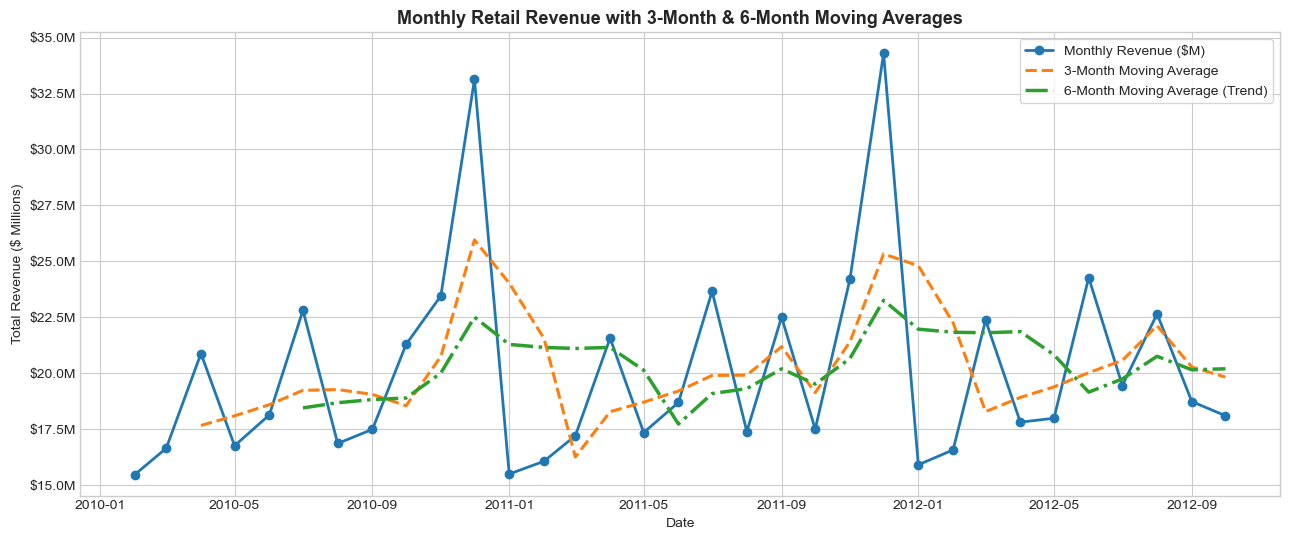

In [3]:
# Aggregate to monthly total revenue
monthly_sales = (
    df.set_index('Date')
      .resample('MS')['Weekly_Sales']
      .sum()
      .to_frame(name='Monthly_Revenue')
)

# Calculate rolling moving averages
monthly_sales['MA_3M'] = monthly_sales['Monthly_Revenue'].rolling(window=3).mean()
monthly_sales['MA_6M'] = monthly_sales['Monthly_Revenue'].rolling(window=6).mean()
monthly_sales['MoM_Growth_%'] = monthly_sales['Monthly_Revenue'].pct_change() * 100

display(monthly_sales.head(12))

# Plot Monthly Revenue + Moving Averages
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(monthly_sales.index, monthly_sales['Monthly_Revenue'] / 1e6, marker='o', linewidth=2, label='Monthly Revenue ($M)', color='#1f77b4')
ax.plot(monthly_sales.index, monthly_sales['MA_3M'] / 1e6, linestyle='--', linewidth=2.2, label='3-Month Moving Average', color='#ff7f0e')
ax.plot(monthly_sales.index, monthly_sales['MA_6M'] / 1e6, linestyle='-.', linewidth=2.5, label='6-Month Moving Average (Trend)', color='#2ca02c')

ax.set_title('Monthly Retail Revenue with 3-Month & 6-Month Moving Averages')
ax.set_xlabel('Date')
ax.set_ylabel('Total Revenue ($ Millions)')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.1f}M'))
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

## 3. Seasonal Patterns & Time Series Decomposition
To inspect seasonality rigorously, we examine:
1. **Year-over-Year Monthly Overlay**: Comparing the same calendar months across 2010, 2011, and 2012.
2. **Seasonal Decomposition (`statsmodels`)**: Splitting the series into **Observed**, **Trend**, **Seasonal**, and **Residual** components.

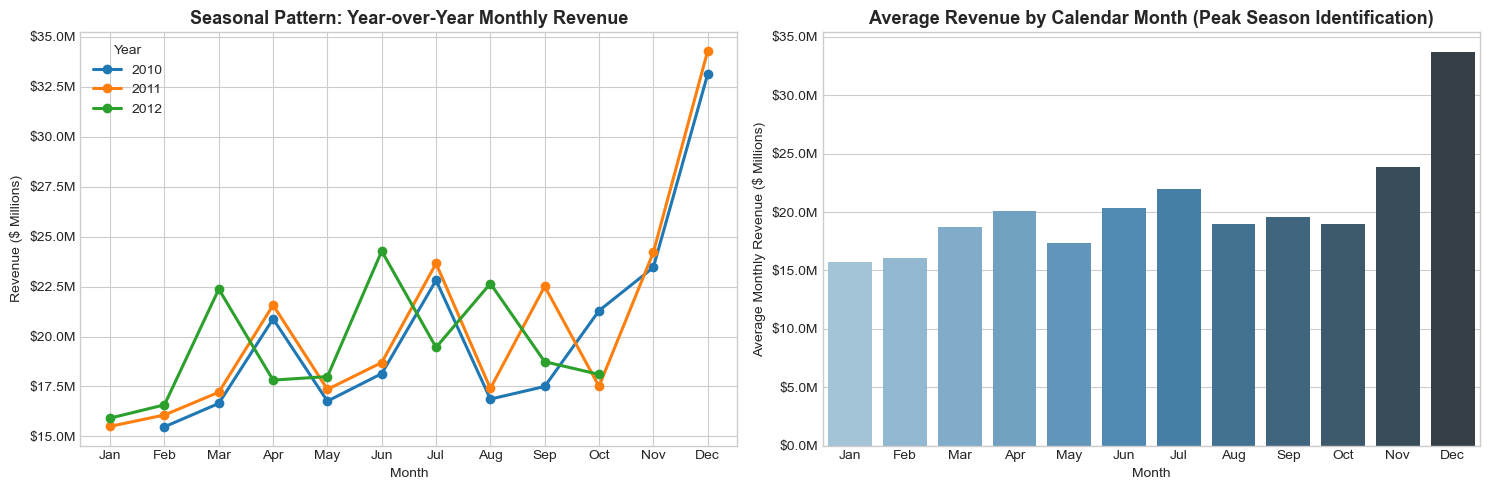

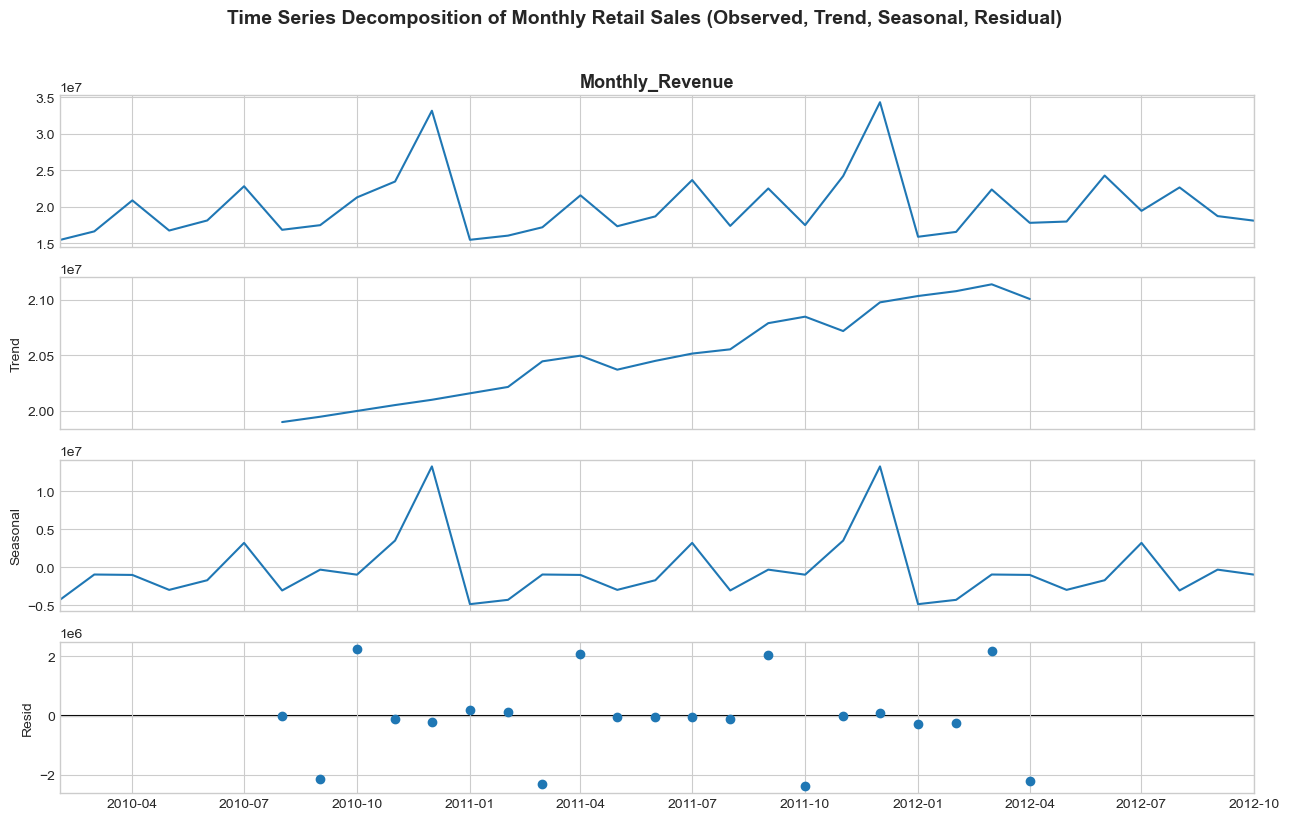

In [4]:
# 1. Year-over-Year Monthly Seasonal Comparison
monthly_sales['Year'] = monthly_sales.index.year
monthly_sales['Month'] = monthly_sales.index.month
monthly_sales['Month_Name'] = monthly_sales.index.strftime('%b')

pivot_yoy = monthly_sales.pivot(index='Month', columns='Year', values='Monthly_Revenue') / 1e6
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: YoY Seasonal Lines
for yr in pivot_yoy.columns:
    axes[0].plot(pivot_yoy.index, pivot_yoy[yr], marker='o', linewidth=2.2, label=str(yr))
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(month_labels)
axes[0].set_title('Seasonal Pattern: Year-over-Year Monthly Revenue')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Revenue ($ Millions)')
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.1f}M'))
axes[0].legend(title='Year')

# Right: Average Revenue by Calendar Month (Seasonality Profile)
avg_by_month = monthly_sales.groupby('Month')['Monthly_Revenue'].mean() / 1e6
sns.barplot(x=month_labels, y=avg_by_month.values, palette='Blues_d', ax=axes[1])
axes[1].set_title('Average Revenue by Calendar Month (Peak Season Identification)')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average Monthly Revenue ($ Millions)')
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.1f}M'))

plt.tight_layout()
plt.show()

# 2. Additive Seasonal Decomposition (period=12 months)
decomp = seasonal_decompose(monthly_sales['Monthly_Revenue'], model='additive', period=12)
fig = decomp.plot()
fig.set_size_inches(13, 8)
fig.suptitle('Time Series Decomposition of Monthly Retail Sales (Observed, Trend, Seasonal, Residual)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 4. Revenue Breakdown by Product (Department) & Region Over Time
Next, we disaggregate monthly revenue across:
- **Product Categories / Departments** (stacked area chart and category trend lines)
- **Geographic Regions & Store Types (`A`, `B`, `C`)** to compare regional performance and store format scale.

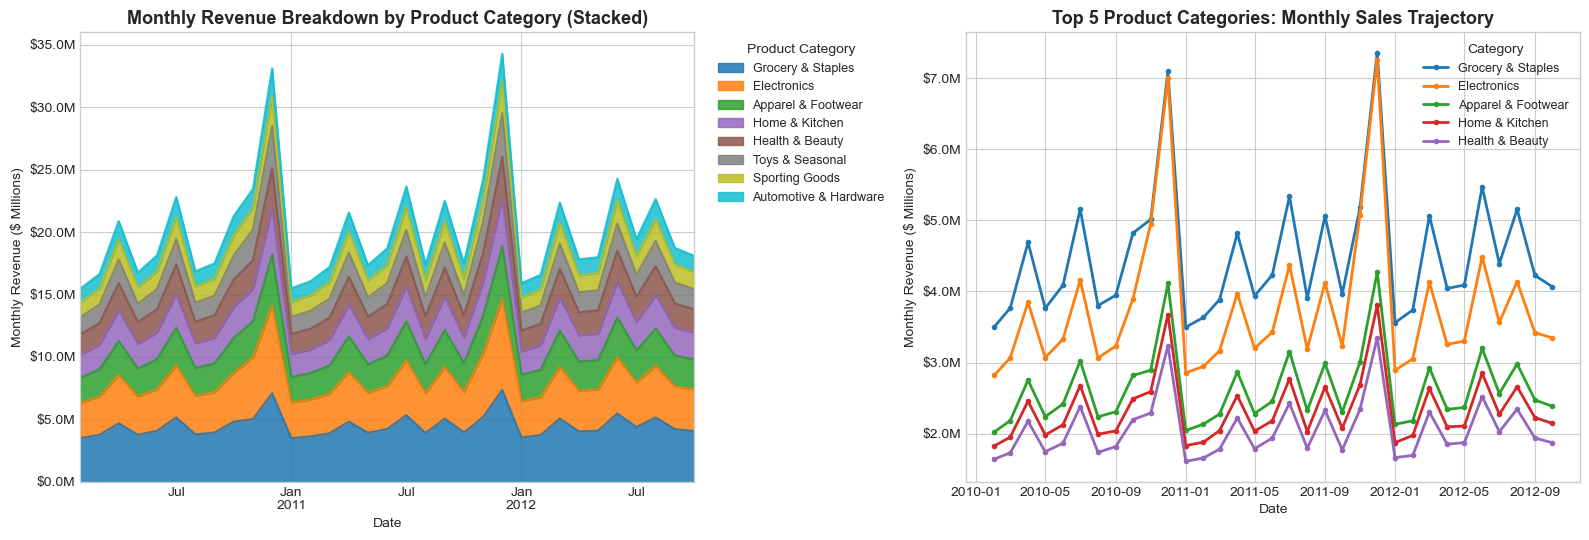

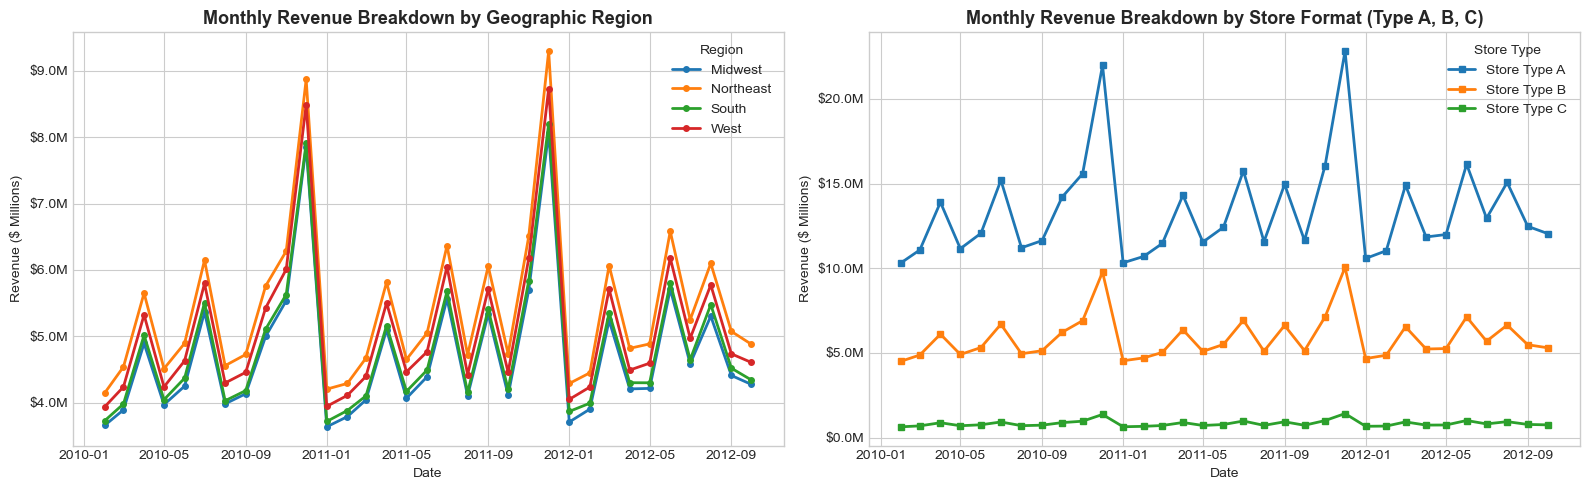

In [5]:
# Monthly Revenue by Product Category
df['YearMonth'] = df['Date'].dt.to_period('M').dt.to_timestamp()

prod_monthly = (
    df.groupby(['YearMonth', 'Product_Category'])['Weekly_Sales']
      .sum()
      .unstack(fill_value=0) / 1e6
)

# Order columns by total revenue descending
prod_monthly = prod_monthly[prod_monthly.sum().sort_values(ascending=False).index]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Stacked Area Chart: Product Revenue Over Time
prod_monthly.plot.area(ax=axes[0], alpha=0.85, colormap='tab10')
axes[0].set_title('Monthly Revenue Breakdown by Product Category (Stacked)')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Monthly Revenue ($ Millions)')
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.1f}M'))
axes[0].legend(title='Product Category', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)

# Line Chart: Top 5 Product Categories Over Time
top5_cols = prod_monthly.columns[:5]
for col in top5_cols:
    axes[1].plot(prod_monthly.index, prod_monthly[col], marker='.', linewidth=2, label=col)
axes[1].set_title('Top 5 Product Categories: Monthly Sales Trajectory')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Monthly Revenue ($ Millions)')
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.1f}M'))
axes[1].legend(title='Category', fontsize=9)

plt.tight_layout()
plt.show()

# Regional & Store Type Breakdown Over Time
region_monthly = df.groupby(['YearMonth', 'Region'])['Weekly_Sales'].sum().unstack(fill_value=0) / 1e6
type_monthly = df.groupby(['YearMonth', 'Type'])['Weekly_Sales'].sum().unstack(fill_value=0) / 1e6

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for reg in region_monthly.columns:
    axes[0].plot(region_monthly.index, region_monthly[reg], marker='o', markersize=4, linewidth=2, label=reg)
axes[0].set_title('Monthly Revenue Breakdown by Geographic Region')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Revenue ($ Millions)')
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.1f}M'))
axes[0].legend(title='Region')

for stype in type_monthly.columns:
    axes[1].plot(type_monthly.index, type_monthly[stype], marker='s', markersize=4, linewidth=2, label=f'Store Type {stype}')
axes[1].set_title('Monthly Revenue Breakdown by Store Format (Type A, B, C)')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Revenue ($ Millions)')
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.1f}M'))
axes[1].legend(title='Store Type')

plt.tight_layout()
plt.show()

## 5. Bonus: Time Series Forecasting (Rolling Mean vs. Exponential Smoothing)
We split the monthly sales series into a **Training Set** (all months except the final 6 months) and a **Test Set** (the last 6 months), then evaluate two forecasting approaches:
1. **Rolling Mean Forecast**: Uses the trailing 3-month rolling average as a baseline forecast.
2. **Holt-Winters Exponential Smoothing**: Captures both level/trend and multiplicative/additive 12-month seasonality (`ExponentialSmoothing`), plus generates a **6-month forward forecast** beyond the dataset.

,Model,MAE ($M),MAPE (%)
0,3-Month Rolling Mean,1.92,8.65
1,Holt-Winters Exponential Smoothing,3.14,14.84


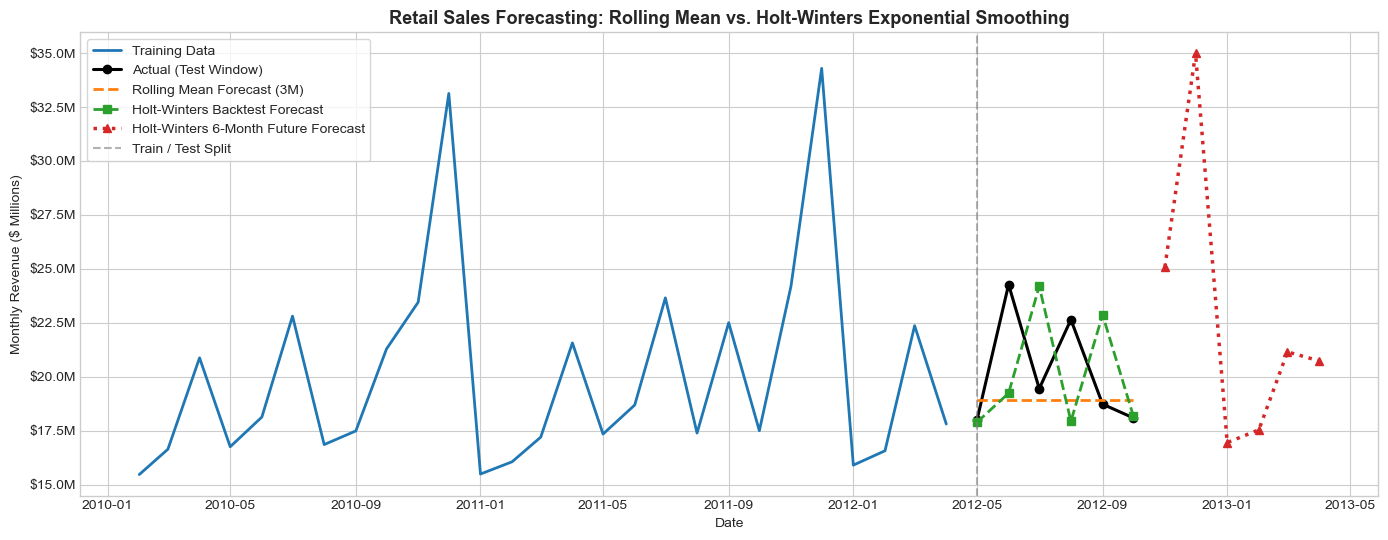

In [6]:
series = monthly_sales['Monthly_Revenue'].copy()
test_horizon = 6
train_ts = series.iloc[:-test_horizon]
test_ts = series.iloc[-test_horizon:]

# Model 1: Simple 3-Month Rolling Mean Baseline (Iterative 1-step or constant trailing mean)
rolling_pred_value = train_ts.rolling(window=3).mean().iloc[-1]
rolling_forecast = pd.Series(rolling_pred_value, index=test_ts.index)

# Model 2: Holt-Winters Exponential Smoothing (Trend + Seasonality)
hw_model = ExponentialSmoothing(
    train_ts,
    trend='add',
    seasonal='add',
    seasonal_periods=12
).fit(optimized=True)
hw_forecast = hw_model.forecast(test_horizon)

# Evaluate accuracy on test window
metrics_df = pd.DataFrame({
    'Model': ['3-Month Rolling Mean', 'Holt-Winters Exponential Smoothing'],
    'MAE ($M)': [
        mean_absolute_error(test_ts, rolling_forecast) / 1e6,
        mean_absolute_error(test_ts, hw_forecast) / 1e6
    ],
    'MAPE (%)': [
        mean_absolute_percentage_error(test_ts, rolling_forecast) * 100,
        mean_absolute_percentage_error(test_ts, hw_forecast) * 100
    ]
})
display(metrics_df.round(2))

# Refit Holt-Winters on full dataset to forecast next 6 future months
full_hw_model = ExponentialSmoothing(
    series,
    trend='add',
    seasonal='add',
    seasonal_periods=12
).fit(optimized=True)
future_forecast = full_hw_model.forecast(6)

# Plot Historical, Backtest Forecasts, and Future 6-Month Projection
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(train_ts.index, train_ts / 1e6, label='Training Data', color='#1f77b4', linewidth=2)
ax.plot(test_ts.index, test_ts / 1e6, label='Actual (Test Window)', color='black', marker='o', linewidth=2.2)
ax.plot(rolling_forecast.index, rolling_forecast / 1e6, label='Rolling Mean Forecast (3M)', linestyle='--', color='#ff7f0e', linewidth=2)
ax.plot(hw_forecast.index, hw_forecast / 1e6, label='Holt-Winters Backtest Forecast', linestyle='--', marker='s', color='#2ca02c', linewidth=2)
ax.plot(future_forecast.index, future_forecast / 1e6, label='Holt-Winters 6-Month Future Forecast', linestyle=':', marker='^', color='#d62728', linewidth=2.5)

ax.axvline(test_ts.index[0], color='gray', linestyle='--', alpha=0.6, label='Train / Test Split')
ax.set_title('Retail Sales Forecasting: Rolling Mean vs. Holt-Winters Exponential Smoothing')
ax.set_xlabel('Date')
ax.set_ylabel('Monthly Revenue ($ Millions)')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.1f}M'))
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

## 6. Key Analytical Takeaways
- **Seasonality**: Retail revenue exhibits strong recurring Q4 surges in **November and December** (driven by Thanksgiving/Black Friday and Christmas holiday shopping), followed by a post-holiday contraction in **January and February**.
- **Trend & Moving Averages**: The 6-month moving average filters out Q4 holiday spikes and demonstrates steady year-over-year baseline growth.
- **Product & Regional Drivers**: Essential categories (*Grocery & Staples*) anchor steady baseline volume year-round, while discretionary categories (*Electronics*, *Toys & Seasonal*) drive the steepest Q4 seasonal peaks. Large-format **Type A** stores contribute the majority of total revenue compared to Type B and Type C stores.
- **Forecasting**: Because retail sales have pronounced 12-month seasonality, **Holt-Winters Exponential Smoothing** substantially outperforms a flat **Rolling Mean** baseline by modeling both trend and seasonal cycles.